# Market edge cases: one step, round numbers

Single market steps with numbers small enough to check by hand. Each section plays
a situation, shows what every participant paid and why, and ends with the
**question it leaves open**. Nothing here changes the market: the notebook only
plays [`LocalEnergyMarket`](../../../core/market/lem.py) and reads its records.

**The setup, the same in every case**

- The thesis network and its 13 participants
  ([`thesis_rural3_p13.json`](../../../config/scenarios/thesis_rural3_p13.json)), but
  every participant's generation and demand is set to 0 except the ones a case names.
- Flat tariffs: the DSO buys at **0.08** (feed-in tariff) and sells at **0.30**
  (utility price), EUR per kWh. One step is one hour, so kWh and kW are the same number.
- Batteries, where a case uses one: **10 kWh, 5 kW**, usable between 1 and 9 kWh,
  efficiency 0.95 each way, starting at 5 kWh.
- The network's other loads (the background) run as in SimBench, at midnight of
  15 June 2016.

**How to read a case**

Two tables per case. The first has one row per participant: what it ordered, where
the energy went (`peer`, `dso`, `untraded`; + is energy it received), and the money
(+ is money it received). `bill` is the step's reward:
`trades + fees + loss charge + untraded`. The second table has one row per trade
with the parts of its fee ([P1] eq. 8). A positive fee is paid to the DSO, a
negative one is paid out by it.

| Section | What it shows | Open point |
|---|---|---|
| [0](#0.-What-behaves-as-documented) | Order limits, clearing stages, battery arithmetic | none |
| [1](#1.-The-loss-charge-near-a-balanced-network) | The loss charge is several times the losses themselves when the network balances | defect |
| [2](#2.-The-same-flow,-three-costs) | Untraded, peer-traded and DSO-cleared energy pay different fees | MP-1e, M-31 |
| [3](#3.-The-imbalance-fee) | The imbalance fee depends on other orders and flips at balance | |
| [4](#4.-Who-pays-for-a-loaded-line) | The power flow charges the trade on the line, not the cause | |
| [5](#5.-The-graph-model's-capacity) | The "paper" capacity split is saturated | MP-4e |
| [6](#6.-Voltage-breaks-first) | The fees barely see the limit that is reached first | |
| [7](#7.-The-zone-bonus) | A same-feeder trade is paid, not charged | M-33, M-34 |
| [8](#8.-Peer-prices-outside-the-tariffs) | The market accepts them | |
| [9](#9.-The-buy-limit-and-own-surplus) | Buying while exporting | MP-2c |
| [10](#10.-Smaller-ones) | Stored energy, ties, tiny orders | MP-1c |

In [1]:
import sys
from copy import deepcopy
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core" / "market").is_dir())
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from core.config import store
from core.config.scenario import BatterySetup
from core.env.reward import net_bill
from core.market.dso import DSO_ID
from core.market.lem import LocalEnergyMarket, OrderIntent

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BASE = store.load(ROOT / "config" / "scenarios" / "thesis_rural3_p13.json")  # read only
BATTERY = BatterySetup(capacity_kwh=10.0, max_power_kw=5.0)
FEE_PARTS = ["congestion", "thermal", "voltage", "transmission", "zone", "imbalance", "peer_charge"]

# The three ways the fees can read the line loading (grid.method)
POWERFLOW = {"method": "powerflow"}
GRAPH_PAPER = {"method": "graph", "graph_capacity": "paper"}
GRAPH_RATINGS = {"method": "graph", "graph_capacity": "ratings"}
METHODS = {"power flow": POWERFLOW, "graph, paper split": GRAPH_PAPER, "graph, line ratings": GRAPH_RATINGS}


def sell(pid, kwh, price, partner=None):
    return OrderIntent(pid, False, price, kwh, partner)


def buy(pid, kwh, price, partner=None):
    return OrderIntent(pid, True, price, kwh, partner)

In [2]:
def market(gen=None, dem=None, soc=None, dso=None, grid=None, batteries=("P2", "P6", "P9")):
    # The thesis market with flat tariffs and everyone silent except gen / dem.
    # gen, dem: {participant: kWh per step}; soc: {participant: battery kWh at the start};
    # dso, grid: settings to change (DsoSetup, GridSetup).
    s = deepcopy(BASE)
    s.dso.prices = {"utility": 0.30, "feed_in": 0.08}
    s.market.partner_preference = False

    for key, value in (dso or {}).items():
        setattr(s.dso, key, value)

    for key, value in (grid or {}).items():
        setattr(s.grid, key, value)

    for p in s.participants:
        p.battery = deepcopy(BATTERY) if p.id in batteries else None

    m = LocalEnergyMarket(s)
    m.reset()

    for pid, p in m.participants.items():
        steps = len(p.generation_kwh)
        p.generation_kwh = [float((gen or {}).get(pid, 0.0))] * steps
        p.demand_kwh = [float((dem or {}).get(pid, 0.0))] * steps

    for pid, kwh in (soc or {}).items():
        m.participants[pid].battery.energy_kwh = kwh

    return m


def step(m, orders=()):
    # Play one step with the given orders.
    return m.step({o.participant_id: o for o in orders})


def people(record, orders=(), who=None):
    # One row per participant: order, energy and money of the step.
    given = {o.participant_id: o for o in orders}
    placed = {o.agent_id: o for o in record.orders}
    fit, utility = record.inputs.feed_in_tariff, record.inputs.utility_price
    rows = []

    for pid, o in record.participants.items():
        active = o.generation_kwh or o.demand_kwh or o.soc_kwh is not None and pid in (who or ())
        if who is None and not (active or pid in given):
            continue
        if who is not None and pid not in who:
            continue

        mine = [t for t in record.trades if pid in (t.buyer_id, t.seller_id)]
        sign = lambda t: 1 if t.buyer_id == pid else -1
        i, v = given.get(pid), placed.get(pid)
        rows.append({
            "id": pid,
            "G": o.generation_kwh,
            "D": o.demand_kwh,
            "order": "-" if i is None else f"{'buy' if i.is_buy else 'sell'} {i.quantity_kwh:g} @ {i.price:g}"
                     + (f" -> {i.partner_id}" if i.partner_id else ""),
            "placed": "-" if i is None else ("nothing" if v is None else f"{v.quantity:.4g} @ {v.price:g}"),
            "peer": sum(sign(t) * t.quantity for t in mine if t.stage < 3),
            "dso": sum(sign(t) * t.quantity for t in mine if t.stage == 3),
            "untraded": -o.external_kwh,
            "battery after": o.soc_kwh,
            "trades EUR": -sum(sign(t) * t.price * t.quantity for t in mine),
            "fees EUR": -(o.fees - o.loss_charge),
            "loss charge EUR": -o.loss_charge,
            "untraded EUR": fit * o.deferred_supply_kwh - utility * o.deferred_demand_kwh,
            "bill EUR": net_bill(record, pid),
        })

    table = pd.DataFrame(rows).set_index("id")
    return table.dropna(axis=1, how="all")


def trades(record):
    # One row per trade, with the parts of its fee (eq. 8).
    rows = []

    for t in record.trades:
        row = {
            "stage": t.stage,
            "seller": t.seller_id,
            "buyer": t.buyer_id,
            "kWh": t.quantity,
            "price": t.price,
            "value EUR": t.quantity * t.price,
            "km": t.distance,
        }
        row.update({part: getattr(t.fee_parts, part) for part in FEE_PARTS})
        row.update({"fee EUR": t.fees, "buyer pays": t.buyer_fee, "seller pays": t.seller_fee})
        rows.append(row)

    table = pd.DataFrame(rows)
    quiet = [part for part in FEE_PARTS if part in table and (table[part].abs() < 1e-12).all()]
    return table.drop(columns=quiet)


def facts(record):
    # The step in one line: the loading the fees read, the measured one, the money check.
    read = record.signal or record.grid
    paid = sum(o.profit for o in record.participants.values())
    return (f"loading the fees read: {read.max_line_loading_percent:.1f} %, "
            f"measured: {record.grid.max_line_loading_percent:.1f} %, "
            f"network losses: {record.grid.losses_kwh:.2f} kWh, "
            f"participants {paid:+.4f} + DSO {record.dso.profit:+.4f} = {paid + record.dso.profit:+.4f} EUR")


def case(title, orders=(), who=None, **setup):
    # Build the market, play one step, show both tables. Returns (market, record).
    m = market(**setup)
    record = step(m, orders)
    display(Markdown(f"**{title}**"))
    display(people(record, orders, who).round(4))
    if record.trades:
        display(trades(record).round(4))
    for note in record.notes:
        print("validation:", note)
    print(facts(record))
    return m, record


# Charts: one look for all of them
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#1a1a19", "#6b6a63", "#e4e3dc"


def axes(title, xlabel, ylabel, width=7.5, height=3.6):
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    return fig, ax

## 0. What behaves as documented

Four cases with nothing to decide, to show the tables and the basic mechanics.

**Who is where.** P3 and P5 hang on the same feeder, 8 m apart. P4 is on another
feeder, 200 m from P3 along the lines.

In [3]:
# P3 has a surplus of 4 kWh (generates 5, uses 1). P5 needs 3, P4 needs 2.
# P3 asks 0.15, P5 bids 0.25: they meet at the average, 0.20. P4 places no order.
HOUSES = dict(gen={"P3": 5}, dem={"P3": 1, "P5": 3, "P4": 2})

_ = case("A peer trade, a rest for the DSO, and one participant without an order",
         orders=[sell("P3", 4, 0.15), buy("P5", 3, 0.25)], **HOUSES)

**A peer trade, a rest for the DSO, and one participant without an order**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,-3,-1,-0.0,0.68,0.0447,-0.0,0.0,0.7247
P4,0.0,2.0,-,-,0,0,2.0,0.00,-0.0000,-0.0,-0.6,-0.6000
P5,0.0,3.0,buy 3 @ 0.25,3 @ 0.25,3,0,-0.0,-0.60,0.0449,-0.0,0.0,-0.5551


,stage,seller,buyer,kWh,price,value EUR,km,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3,0.20,0.60,0.0084,0.0002,-0.09,-0.0898,-0.0449,-0.0449
1,3,P3,DSO,1,0.08,0.08,0.0921,0.0002,0.00,0.0002,0.0000,0.0002


loading the fees read: 2.4 %, measured: 2.4 %, network losses: 1.27 kWh, participants +0.1696 + DSO -0.1696 = -0.0000 EUR


Reading it: P3 sold 3 kWh to P5 at 0.20 (stage 2, the auction) and its last 1 kWh
to the DSO at 0.08 (stage 3). P4 placed no order, so its 2 kWh came from the grid
untraded at 0.30. The peer trade's fee is **negative**: the same-feeder bonus
(`zone`, 15 % of the trade's value) is larger than the rest. More on that in
[section 7](#7.-The-zone-bonus).

In [4]:
_ = case("Orders beyond what a participant has: cut to its surplus and deficit",
         orders=[sell("P3", 10, 0.15), buy("P5", 10, 0.25)], **HOUSES)

_ = case("Orders on the wrong side (P3 has a surplus and buys, P5 has a deficit and sells): dropped",
         orders=[buy("P3", 2, 0.25), sell("P5", 2, 0.15)], **HOUSES)

_ = case("P3 and P5 name each other, but the bid is below the ask: no stage 1, P3 trades with P4 in the auction",
         orders=[sell("P3", 4, 0.25, "P5"), buy("P5", 3, 0.15, "P3"), buy("P4", 2, 0.28)], **HOUSES)

**Orders beyond what a participant has: cut to its surplus and deficit**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 10 @ 0.15,4 @ 0.15,-3.0,-1.0,-0.0,0.68,0.0447,-0.0,0.0,0.7247
P4,0.0,2.0,-,-,0.0,0.0,2.0,0.00,-0.0000,-0.0,-0.6,-0.6000
P5,0.0,3.0,buy 10 @ 0.25,3 @ 0.25,3.0,0.0,-0.0,-0.60,0.0449,-0.0,0.0,-0.5551


,stage,seller,buyer,kWh,price,value EUR,km,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3.0,0.20,0.60,0.0084,0.0002,-0.09,-0.0898,-0.0449,-0.0449
1,3,P3,DSO,1.0,0.08,0.08,0.0921,0.0002,0.00,0.0002,0.0000,0.0002


validation: P3: 10.00 kWh limited to 4.00
validation: P5: 10.00 kWh limited to 3.00
loading the fees read: 2.4 %, measured: 2.4 %, network losses: 1.27 kWh, participants +0.1696 + DSO -0.1696 = -0.0000 EUR


**Orders on the wrong side (P3 has a surplus and buys, P5 has a deficit and sells): dropped**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,buy 2 @ 0.25,nothing,0,0,-4.0,0,-0.0,-0.0,0.32,0.32
P4,0.0,2.0,-,-,0,0,2.0,0,-0.0,-0.0,-0.60,-0.60
P5,0.0,3.0,sell 2 @ 0.15,nothing,0,0,3.0,0,-0.0,-0.0,-0.90,-0.90


validation: P3: 2.00 kWh limited to 0.00
validation: P5: 2.00 kWh limited to 0.00
loading the fees read: 2.4 %, measured: 2.4 %, network losses: 1.27 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR


**P3 and P5 name each other, but the bid is below the ask: no stage 1, P3 trades with P4 in the auction**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.25 -> P5,4 @ 0.25,-2,-2,-0.0,0.69,-0.0262,-0.0,0.0,0.6638
P4,0.0,2.0,buy 2 @ 0.28,2 @ 0.28,2,0,-0.0,-0.53,-0.0018,-0.0,0.0,-0.5318
P5,0.0,3.0,buy 3 @ 0.15 -> P3,3 @ 0.15,0,3,-0.0,-0.90,-0.0027,-0.0,0.0,-0.9027


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,imbalance,fee EUR,buyer pays,seller pays
0,2,P3,P4,2,0.265,0.53,0.1996,0.0004,0.0032,0.000,0.0035,0.0018,0.0018
1,3,P3,DSO,2,0.080,0.16,0.0921,0.0000,0.0004,0.024,0.0244,0.0000,0.0244
2,3,DSO,P5,3,0.300,0.90,0.1005,0.0000,0.0027,0.000,0.0027,0.0027,0.0000


loading the fees read: 2.4 %, measured: 2.4 %, network losses: 1.27 kWh, participants -0.7707 + DSO +0.7707 = +0.0000 EUR


**The battery.** A battery owner places no order for the battery itself: after its
trades, what is left at its bus charges or discharges the battery
([`Participant.settle`](../../../core/market/agent/der.py)). With 5 kWh stored and a
floor of 1 kWh, it can deliver $(5 - 1) \cdot 0.95 = 3.8$ kWh at the bus; with a
ceiling of 9 kWh it can take $(9 - 5) / 0.95 = 4.21$ kWh.

In [5]:
_ = case("Deficit 3 kWh, no order: the battery covers it (3 / 0.95 = 3.16 kWh leave the battery)",
         dem={"P2": 3}, soc={"P2": 5})

_ = case("Deficit 3 kWh, buys as much as it may: 3 for the load + 4.21 to fill the battery",
         orders=[buy("P2", 100, 0.30)], dem={"P2": 3}, soc={"P2": 5})

_ = case("Deficit 6 kWh, no order: the battery gives its 3.8, the other 2.2 come untraded",
         dem={"P2": 6}, soc={"P2": 5})

**Deficit 3 kWh, no order: the battery covers it (3 / 0.95 = 3.16 kWh leave the battery)**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,3.0,-,-,0,0,-0.0,1.8421,0,-0.0,-0.0,0.0,0.0


loading the fees read: 1.4 %, measured: 1.4 %, network losses: 1.27 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR


**Deficit 3 kWh, buys as much as it may: 3 for the load + 4.21 to fill the battery**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,3.0,buy 100 @ 0.3,7.211 @ 0.3,0,7.2105,-0.0,9.0,-2.1632,-0.0353,-0.0,0.0,-2.1985


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,fee EUR,buyer pays,seller pays
0,3,DSO,P2,7.2105,0.3,2.1632,0.3975,0.0095,0.0258,0.0353,0.0353,0.0


validation: P2: 100.00 kWh limited to 7.21
loading the fees read: 5.1 %, measured: 5.1 %, network losses: 1.31 kWh, participants -2.1985 + DSO +2.1985 = +0.0000 EUR


**Deficit 6 kWh, no order: the battery gives its 3.8, the other 2.2 come untraded**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,6.0,-,-,0,0,2.2,1.0,0,-0.0,-0.0,-0.66,-0.66


loading the fees read: 2.5 %, measured: 2.5 %, network losses: 1.28 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR


## 1. The loss charge near a balanced network

With `dso.losses = "bcdla"` (the `powerflow` arm of the thesis experiment), the
step's measured losses are shared among the participants by their currents, and
each pays its share at the utility price (MP-4j). No order is needed: the charge
follows what a participant physically did.

**The case.** P13 generates 60 kWh at the end of one feeder, P11 consumes on
another. Nobody places an order. Only P11's consumption changes from case to case.

In [6]:
BCDLA = {"losses": "bcdla"}

_ = case("P13 generates 60, P11 consumes 60", dso=BCDLA, gen={"P13": 60}, dem={"P11": 60})
_ = case("P13 generates 60, P11 consumes 44", dso=BCDLA, gen={"P13": 60}, dem={"P11": 44})

**P13 generates 60, P11 consumes 60**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,60.0,-,-,0,0,60.0,0,-0.0,-2.0019,-18.0,-20.0019
P13,60.0,0.0,-,-,0,0,-60.0,0,-0.0,1.1791,4.8,5.9791


loading the fees read: 32.9 %, measured: 32.9 %, network losses: 3.77 kWh, participants -0.8228 + DSO +0.8228 = +0.0000 EUR


**P13 generates 60, P11 consumes 44**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,44.0,-,-,0,0,44.0,0,-0.0,2.9480,-13.2,-10.2520
P13,60.0,0.0,-,-,0,0,-60.0,0,-0.0,-4.5705,4.8,0.2295


loading the fees read: 30.6 %, measured: 30.6 %, network losses: 3.16 kWh, participants -1.6224 + DSO +1.6224 = +0.0000 EUR


Look at `loss charge EUR`. With 60 against 60, P13 is **credited** and P11 charged.
With 60 against 44 the signs are the other way round and the amounts are larger,
although the network's losses went *down*. The sweep below shows the whole picture.
The network's other loads use about 13 kWh in this hour, so the community is
balanced, with nothing exchanged with the upstream grid, when P11 consumes about 47.

,exchange with upstream kWh,network losses kWh,P13 share kWh,P11 share kWh,P13 pays EUR,P11 pays EUR
P11 consumes kWh,,,,,,
0,-46.19,2.53,2.86,0.00,0.86,0.00
10,-36.17,2.54,3.26,-0.31,0.98,-0.09
20,-26.08,2.64,3.96,-0.79,1.19,-0.24
30,-15.91,2.80,5.48,-1.87,1.64,-0.56
40,-5.67,3.04,10.62,-5.89,3.19,-1.77
44,-1.55,3.16,15.23,-9.83,4.57,-2.95
46,0.51,3.23,8.56,-4.80,2.57,-1.44
48,2.58,3.30,-9.34,9.85,-2.80,2.96
50,4.65,3.37,-11.91,12.39,-3.57,3.72


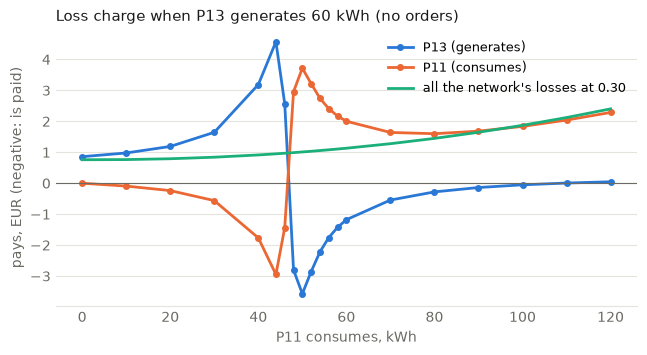

In [7]:
rows = []
for demand in list(range(0, 41, 10)) + list(range(44, 61, 2)) + list(range(70, 121, 10)):
    m = market(dso=BCDLA, gen={"P13": 60}, dem={"P11": demand})
    r = step(m)
    rows.append({
        "P11 consumes kWh": demand,
        "exchange with upstream kWh": r.grid.external_grid_kwh,
        "network losses kWh": r.grid.losses_kwh,
        "P13 share kWh": r.grid.loss_shares_kwh.get("P13", 0.0),
        "P11 share kWh": r.grid.loss_shares_kwh.get("P11", 0.0),
        "P13 pays EUR": r.participants["P13"].loss_charge,
        "P11 pays EUR": r.participants["P11"].loss_charge,
    })

sweep = pd.DataFrame(rows).set_index("P11 consumes kWh")
display(sweep.round(2))

fig, ax = axes("Loss charge when P13 generates 60 kWh (no orders)", "P11 consumes, kWh", "pays, EUR (negative: is paid)")
ax.plot(sweep.index, sweep["P13 pays EUR"], color=BLUE, linewidth=2, marker="o", markersize=4, label="P13 (generates)")
ax.plot(sweep.index, sweep["P11 pays EUR"], color=ORANGE, linewidth=2, marker="o", markersize=4, label="P11 (consumes)")
ax.plot(sweep.index, sweep["network losses kWh"] * 0.30, color=AQUA, linewidth=2, label="all the network's losses at 0.30")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.legend(frameon=False, fontsize=9)
plt.show()

**Why.** The rule ([`BranchCurrentDecomposition.shares`](../../../core/grid/losses.py))
gives element $e$ this share of branch $b$'s loss:

$$
\text{share}_{e,b} = \frac{\operatorname{Re}\left(I_e \, \overline{I_b}\right)}{|I_b|^2} \cdot \text{loss}_b
$$

where $I_e$ is the element's current and $I_b$ the branch's, the sum of everything
below it. For a line that is fine: when $I_b$ is small, the line's loss is small
too (it goes with $|I_b|^2$). The **transformer** is different. It loses about
1.26 kW even with nothing connected (its no-load loss), so $\text{loss}_b$ stays
at 1.26 while $|I_b|$ goes to zero as the community balances. The ratio
$I_e / I_b$ then becomes very large. Here the background's reactive current keeps
$|I_b|$ from reaching zero; with the background switched off, 5 kWh generated
against 5 kWh consumed gave a charge of 94.57 EUR and a credit of 94.19 EUR. The next cell shows the transformer's part alone.

In [8]:
from core.grid import losses as loss_rules


def transformer_part(demand):
    # P13's and P11's share of the transformer's loss alone, kW
    m = market(dso=BCDLA, gen={"P13": 60}, dem={"P11": demand})
    step(m)
    net = m.grid._net
    current = loss_rules._element_currents(net)
    below = loss_rules._elements_below(net, current)
    loss_kw = loss_rules.branch_losses_kw(net)[("trafo", 0)]
    mine = below[("trafo", 0)]
    total = sum((current[e] for e in mine), 0j)
    ranked = sorted(((current[e] * total.conjugate()).real / abs(total) ** 2 * loss_kw for e in mine))
    return {"P11 consumes kWh": demand, "transformer loss kW": loss_kw, "|I_b| per unit": abs(total),
            "largest credit kW": ranked[0], "largest share kW": ranked[-1]}


display(pd.DataFrame([transformer_part(d) for d in (0, 40, 44, 48, 50, 60, 120)]).set_index("P11 consumes kWh").round(3))

,transformer loss kW,|I_b| per unit,largest credit kW,largest share kW
P11 consumes kWh,,,,
0,1.325,0.046,-0.027,1.635
40,1.262,0.007,-6.450,9.394
44,1.261,0.004,-10.508,14.007
48,1.261,0.003,-10.564,9.042
50,1.261,0.004,-13.134,11.508
60,1.266,0.014,-5.159,5.397
120,1.434,0.076,-1.079,2.304


The transformer's loss is the same 1.3 kW in every row; what changes is how it is
split. **On the thesis days this has not happened**: without orders, the closest the
exchange with upstream came to zero on 15 and 16 June and 1 July was 4.7 kWh, and
the largest single charge was 0.23 EUR. It is a latent case, reached when the
community's generation and consumption cancel within a step.

> **Question.** Share the line losses only and leave the transformer's loss out
> (or share its no-load part some other way, e.g. equally)?

## 2. The same flow, three costs

P13 generates 60 kWh, P11 consumes 60 kWh. Physically the three cases below are
identical: the same power flows through the same lines. They differ only in what
the two wrote into the order book. Fees from the power flow, losses per trade
(`dso.losses = "trades"`, the default).

**no orders**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,60.0,-,-,0,0,60.0,0,-0.0,-0.0,-18.0,-18.0
P13,60.0,0.0,-,-,0,0,-60.0,0,-0.0,-0.0,4.8,4.8


loading the fees read: 32.9 %, measured: 32.9 %, network losses: 3.77 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR


**traded with each other at 0.20**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,60.0,buy 60 @ 0.2,60 @ 0.2,60,0,-0.0,-12.0,-1.3219,-0.0,0.0,-13.3219
P13,60.0,0.0,sell 60 @ 0.2,60 @ 0.2,-60,0,-0.0,12.0,-1.3219,-0.0,0.0,10.6781


,stage,seller,buyer,kWh,price,value EUR,km,thermal,voltage,transmission,fee EUR,buyer pays,seller pays
0,2,P13,P11,60,0.2,12.0,0.5662,1.9275,0.5124,0.2038,2.6437,1.3219,1.3219


... (2 outputs left out)

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P11,0.0,60.0,buy 60 @ 0.15,60 @ 0.15,0,60,-0.0,-18.0,-3.4231,-0.0,0.0,-21.4231
P13,60.0,0.0,sell 60 @ 0.25,60 @ 0.25,0,-60,-0.0,4.8,-0.7825,-0.0,0.0,4.0175


,stage,seller,buyer,kWh,price,value EUR,km,thermal,voltage,transmission,fee EUR,buyer pays,seller pays
0,3,P13,DSO,60,0.08,4.8,0.2947,0.6378,0.1022,0.0424,0.7825,0.0000,0.7825
1,3,DSO,P11,60,0.30,18.0,0.2715,2.8912,0.3852,0.1466,3.4231,3.4231,0.0000


loading the fees read: 32.9 %, measured: 32.9 %, network losses: 3.77 kWh, participants -17.4055 + DSO +17.4055 = -0.0000 EUR


,measured loading %,fees paid EUR,P13 bill EUR,P11 bill EUR,team bill EUR
situation,,,,,
no orders,32.85,0.00,4.80,-18.00,-13.20
traded with each other at 0.20,32.85,2.64,10.68,-13.32,-2.64
"both order, prices do not meet (DSO clears)",32.85,4.21,4.02,-21.42,-17.41


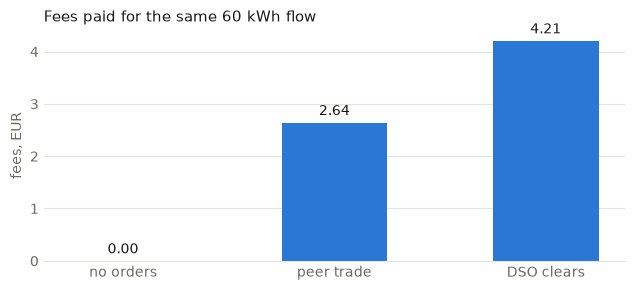

In [9]:
BIG = dict(gen={"P13": 60}, dem={"P11": 60})
situations = {
    "no orders": [],
    "traded with each other at 0.20": [sell("P13", 60, 0.20), buy("P11", 60, 0.20)],
    "both order, prices do not meet (DSO clears)": [sell("P13", 60, 0.25), buy("P11", 60, 0.15)],
}
rows = []
for name, orders in situations.items():
    m, r = case(name, orders=orders, **BIG)
    rows.append({
        "situation": name,
        "measured loading %": r.grid.max_line_loading_percent,
        "fees paid EUR": sum(o.fees for o in r.participants.values()),
        "P13 bill EUR": net_bill(r, "P13"),
        "P11 bill EUR": net_bill(r, "P11"),
        "team bill EUR": net_bill(r, "P13") + net_bill(r, "P11"),
    })

same_flow = pd.DataFrame(rows).set_index("situation")
display(same_flow.round(2))

fig, ax = axes("Fees paid for the same 60 kWh flow", "", "fees, EUR", height=3.0)
bars = ax.bar(["no orders", "peer trade", "DSO clears"], same_flow["fees paid EUR"], color=BLUE, width=0.5)
ax.bar_label(bars, fmt="%.2f", color=INK, padding=3)
plt.show()

Two things to see.

1. **An order that the DSO clears pays the path's fees (M-31); the same energy
   without an order pays none (MP-1e).** The cheapest answer to any fee is to stop
   ordering, which changes no flow.
2. **Fees are a share of the trade's value**, quantity × price. In the third case
   the buyer's 60 kWh at 0.30 pay about four times the fee of the seller's 60 kWh
   at 0.08, on a path of the same kind.

> **Question.** Charge the path's fees on untraded energy too, or charge none on
> orders the DSO clears?

## 3. The imbalance fee

A trade with the DSO pays 15 % of its value, times $\min(q / |B|, 1)$, when it
"worsens" the order book's balance $B$ (offered minus asked;
[`Dso.imbalance_fee`](../../../core/market/dso.py), [P1] eq. 8b, 8h): the DSO
selling while more is offered than asked, or buying while more is asked than
offered.

**The case.** P3 offers 4 kWh at 0.25, P5 bids 0.15: the prices do not meet, so
the DSO clears both. Only P5's quantity changes.

In [10]:
ALMOST = dict(gen={"P3": 5}, dem={"P3": 1, "P5": 6})

_ = case("P5 asks for 4.01 kWh: the book is short by 0.01",
         orders=[sell("P3", 4, 0.25), buy("P5", 4.01, 0.15)], **ALMOST)
_ = case("P5 asks for 3.99 kWh: the book is long by 0.01",
         orders=[sell("P3", 4, 0.25), buy("P5", 3.99, 0.15)], **ALMOST)

**P5 asks for 4.01 kWh: the book is short by 0.01**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.25,4 @ 0.25,0,-4.00,-0.00,0.320,-0.0489,-0.0,0.000,0.2711
P5,0.0,6.0,buy 4.01 @ 0.15,4.01 @ 0.15,0,4.01,1.99,-1.203,-0.0040,-0.0,-0.597,-1.8040


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,imbalance,fee EUR,buyer pays,seller pays
0,3,P3,DSO,4.00,0.08,0.320,0.0921,0.0001,0.0009,0.048,0.0489,0.000,0.0489
1,3,DSO,P5,4.01,0.30,1.203,0.1005,0.0004,0.0036,0.000,0.0040,0.004,0.0000


loading the fees read: 3.1 %, measured: 3.1 %, network losses: 1.27 kWh, participants -0.9359 + DSO +0.9359 = +0.0000 EUR


**P5 asks for 3.99 kWh: the book is long by 0.01**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.25,4 @ 0.25,0,-4.00,-0.00,0.320,-0.0009,-0.0,0.000,0.3191
P5,0.0,6.0,buy 3.99 @ 0.15,3.99 @ 0.15,0,3.99,2.01,-1.197,-0.1835,-0.0,-0.603,-1.9835


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,imbalance,fee EUR,buyer pays,seller pays
0,3,P3,DSO,4.00,0.08,0.320,0.0921,0.0001,0.0009,0.0000,0.0009,0.0000,0.0009
1,3,DSO,P5,3.99,0.30,1.197,0.1005,0.0004,0.0036,0.1796,0.1835,0.1835,0.0000


loading the fees read: 3.1 %, measured: 3.1 %, network losses: 1.27 kWh, participants -1.0615 + DSO +1.0615 = +0.0000 EUR


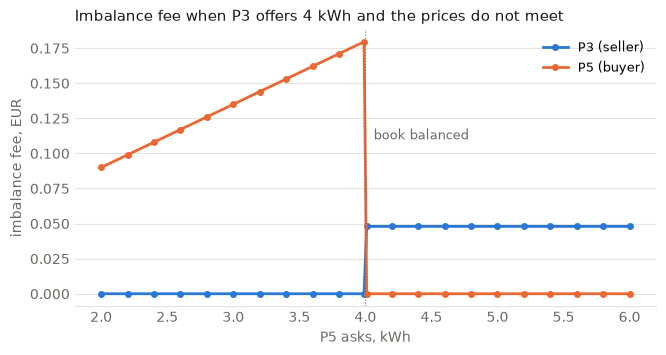

In [11]:
rows = []
for q in sorted([n / 10 for n in range(20, 61, 2) if n != 40] + [3.99, 4.01]):
    m = market(**ALMOST)
    r = step(m, [sell("P3", 4, 0.25), buy("P5", q, 0.15)])
    fee = {t.seller_id if t.buyer_id == DSO_ID else t.buyer_id: t.fee_parts.imbalance for t in r.trades}
    rows.append({"P5 asks kWh": q, "P3 (seller)": fee.get("P3", 0.0), "P5 (buyer)": fee.get("P5", 0.0)})

imbalance = pd.DataFrame(rows).set_index("P5 asks kWh")

fig, ax = axes("Imbalance fee when P3 offers 4 kWh and the prices do not meet", "P5 asks, kWh", "imbalance fee, EUR")
ax.plot(imbalance.index, imbalance["P3 (seller)"], color=BLUE, linewidth=2, marker="o", markersize=4, label="P3 (seller)")
ax.plot(imbalance.index, imbalance["P5 (buyer)"], color=ORANGE, linewidth=2, marker="o", markersize=4, label="P5 (buyer)")
ax.axvline(4, color=MUTED, linewidth=0.8, linestyle=":")
ax.annotate("book balanced", (4, 0.11), xytext=(6, 0), textcoords="offset points", ha="left", fontsize=9, color=MUTED)
ax.legend(frameon=False, fontsize=9)
plt.show()

At 4 kWh the fee jumps from one participant to the other (the two points next to the line are 3.99 and 4.01 kWh). And it reaches a
participant through **somebody else's** order: below, P3's fee on the 1 kWh it
sells to the DSO changes only because P4, on another feeder, adds a low bid.

In [12]:
_, without = case("P4 places no order", orders=[sell("P3", 4, 0.15), buy("P5", 3, 0.25)], **HOUSES)
_, with_p4 = case("P4 bids 0.10 for its 2 kWh (below every ask, so the DSO clears it)",
                  orders=[sell("P3", 4, 0.15), buy("P5", 3, 0.25), buy("P4", 2, 0.10)], **HOUSES)

**P4 places no order**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,-3,-1,-0.0,0.68,0.0447,-0.0,0.0,0.7247
P4,0.0,2.0,-,-,0,0,2.0,0.00,-0.0000,-0.0,-0.6,-0.6000
P5,0.0,3.0,buy 3 @ 0.25,3 @ 0.25,3,0,-0.0,-0.60,0.0449,-0.0,0.0,-0.5551


,stage,seller,buyer,kWh,price,value EUR,km,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3,0.20,0.60,0.0084,0.0002,-0.09,-0.0898,-0.0449,-0.0449
1,3,P3,DSO,1,0.08,0.08,0.0921,0.0002,0.00,0.0002,0.0000,0.0002


loading the fees read: 2.4 %, measured: 2.4 %, network losses: 1.27 kWh, participants +0.1696 + DSO -0.1696 = -0.0000 EUR


**P4 bids 0.10 for its 2 kWh (below every ask, so the DSO clears it)**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,-3,-1,-0.0,0.68,0.0327,-0.0,0.0,0.7127
P4,0.0,2.0,buy 2 @ 0.1,2 @ 0.1,0,2,-0.0,-0.60,-0.0024,-0.0,0.0,-0.6024
P5,0.0,3.0,buy 3 @ 0.25,3 @ 0.25,3,0,-0.0,-0.60,0.0449,-0.0,0.0,-0.5551


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,imbalance,fee EUR,buyer pays,seller pays
0,2,P3,P5,3,0.20,0.60,0.0084,0.0000,0.0002,-0.09,0.000,-0.0898,-0.0449,-0.0449
1,3,P3,DSO,1,0.08,0.08,0.0921,0.0000,0.0002,0.00,0.012,0.0122,0.0000,0.0122
2,3,DSO,P4,2,0.30,0.60,0.1075,0.0004,0.0019,0.00,0.000,0.0024,0.0024,0.0000


loading the fees read: 2.4 %, measured: 2.4 %, network losses: 1.27 kWh, participants -0.4447 + DSO +0.4447 = +0.0000 EUR


> **Question.** Keep the imbalance fee as it is, drop it, or make it change
> smoothly through the balanced book?

## 4. Who pays for a loaded line

The congestion and thermal parts of a trade's fee read the highest loading on the
lines **between the two traders** ([`Dso.fees_of`](../../../core/market/dso.py)).
The two grid methods differ in where that loading comes from: the power flow
(everything on the network) or the graph model (the step's trades only).

**The case.** P13 exports 60 kWh **untraded** and loads its feeder. P10 sells
3 kWh to P12, 11 m apart on the same feeder.

In [13]:
LOADED = dict(gen={"P13": 60, "P10": 3}, dem={"P11": 60, "P12": 3}, batteries=())
rows = []
for name, method in METHODS.items():
    m, r = case(f"[{name}] P13's 60 kWh untraded, P10 sells 3 kWh to P12",
                orders=[sell("P10", 3, 0.20), buy("P12", 3, 0.20)], grid=method, **LOADED)
    t = r.trades[0]
    rows.append({
        "fees read from": name,
        "loading read %": (r.signal or r.grid).max_line_loading_percent,
        "measured %": r.grid.max_line_loading_percent,
        "thermal fee of the 3 kWh trade": t.fee_parts.thermal,
        "as share of its value": t.fee_parts.thermal / (t.quantity * t.price),
        "fees P13 pays": r.participants["P13"].fees,
    })

display(pd.DataFrame(rows).set_index("fees read from").round(4))

**[power flow] P13's 60 kWh untraded, P10 sells 3 kWh to P12**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P10,3.0,0.0,sell 3 @ 0.2,3 @ 0.2,-3,0,-0.0,0.6,0.0002,-0.0,0.0,0.6002
P11,0.0,60.0,-,-,0,0,60.0,0.0,-0.0000,-0.0,-18.0,-18.0000
P12,0.0,3.0,buy 3 @ 0.2,3 @ 0.2,3,0,-0.0,-0.6,0.0002,-0.0,0.0,-0.5998
P13,60.0,0.0,-,-,0,0,-60.0,0.0,-0.0000,-0.0,4.8,4.8000


,stage,seller,buyer,kWh,price,value EUR,km,thermal,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P10,P12,3,0.2,0.6,0.0112,0.0889,0.0005,0.0002,-0.09,-0.0004,-0.0002,-0.0002


loading the fees read: 32.9 %, measured: 32.9 %, network losses: 3.77 kWh, participants +0.0004 + DSO -0.0004 = +0.0000 EUR


**[graph, paper split] P13's 60 kWh untraded, P10 sells 3 kWh to P12**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P10,3.0,0.0,sell 3 @ 0.2,3 @ 0.2,-3,0,-0.0,0.6,0.0447,-0.0,0.0,0.6447
P11,0.0,60.0,-,-,0,0,60.0,0.0,-0.0000,-0.0,-18.0,-18.0000
P12,0.0,3.0,buy 3 @ 0.2,3 @ 0.2,3,0,-0.0,-0.6,0.0447,-0.0,0.0,-0.5553
P13,60.0,0.0,-,-,0,0,-60.0,0.0,-0.0000,-0.0,4.8,4.8000


... (3 outputs left out)

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P10,3.0,0.0,sell 3 @ 0.2,3 @ 0.2,-3,0,-0.0,0.6,0.0447,-0.0,0.0,0.6447
P11,0.0,60.0,-,-,0,0,60.0,0.0,-0.0000,-0.0,-18.0,-18.0000
P12,0.0,3.0,buy 3 @ 0.2,3 @ 0.2,3,0,-0.0,-0.6,0.0447,-0.0,0.0,-0.5553
P13,60.0,0.0,-,-,0,0,-60.0,0.0,-0.0000,-0.0,4.8,4.8000


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P10,P12,3,0.2,0.6,0.0112,0.0005,0.0002,-0.09,-0.0893,-0.0447,-0.0447


loading the fees read: 1.6 %, measured: 32.9 %, network losses: 3.77 kWh, participants +0.0893 + DSO -0.0893 = -0.0000 EUR


,loading read %,measured %,thermal fee of the 3 kWh trade,as share of its value,fees P13 pays
fees read from,,,,,
power flow,32.85,32.85,0.0889,0.1482,0.0
"graph, paper split",2.98,32.85,0.0000,0.0000,0.0
"graph, line ratings",1.60,32.85,0.0000,0.0000,0.0


With the power flow, the small local trade pays a thermal fee for a loading it did
not cause, and P13, who caused it, pays nothing (it has no trade). With the graph
model the untraded flow does not exist: the fees read 3 % or less where 32.9 % was
measured.

**Does the choice of partner matter?** P7 needs 60 kWh. P13, 29 m away on the same
feeder, and P1, on another feeder, both generate 60 kWh. P7 buys from one or the
other; the flows are the same either way.

In [14]:
CHOICE = dict(gen={"P13": 60, "P1": 60}, dem={"P7": 60})
rows = []
for name, method in METHODS.items():
    for seller, where in (("P1", "another feeder"), ("P13", "its neighbour")):
        m = market(grid=method, **CHOICE)
        r = step(m, [sell(seller, 60, 0.20), buy("P7", 60, 0.20)])
        t = r.trades[0]
        row = {"fees read from": name, "P7 buys from": f"{seller}, {where}", "loading read %": (r.signal or r.grid).max_line_loading_percent,
               "measured %": r.grid.max_line_loading_percent}
        row.update({part: getattr(t.fee_parts, part) for part in ("congestion", "thermal", "voltage", "transmission", "zone")})
        row["fee EUR"] = t.fees
        rows.append(row)

display(pd.DataFrame(rows).set_index(["fees read from", "P7 buys from"]).round(3))

loading read %  measured %  congestion  thermal  voltage  transmission  zone  fee EUR
fees read from      P7 buys from                                                                                             
power flow          P1, another feeder           31.17       31.17         0.0    1.642    0.106         0.136   0.0    1.884
                    P13, its neighbour           31.17       31.17         0.0    1.676    0.025         0.010  -1.8   -0.089
graph, paper split  P1, another feeder          465.17       31.17         1.2    3.600    0.106         0.136   0.0    5.042
                    P13, its neighbour          103.84       31.17         1.2    3.600    0.025         0.010  -1.8    3.036
graph, line ratings P1, another feeder           32.08       31.17         0.0    1.812    0.106         0.136   0.0    2.054
                    P13, its neighbour           32.08       31.17         0.0    1.812    0.025         0.010  -1.8    0.048

With the power flow the thermal part is almost the same for both partners, because
the lines carry the same power whoever is named. What separates the two is the
same-feeder bonus. With the graph model the trade's own path sets the loading, so
the partner matters much more.

> **Question.** Is this the contrast between the two methods that the thesis wants
> to show? It is what the main result will measure.

## 5. The graph model's capacity

The graph model divides each line's traded power by a capacity
([`core/grid/graph.py`](../../../core/grid/graph.py)). `"paper"` spreads a total over
the lines in inverse proportion to their length; `"ratings"` uses each line's own
rating. The total of `"paper"` has no value in [P1] (MP-4e); here it is the sum
of the ratings.

**The case.** P13 sells to P11, on another feeder, at 0.20. Only the size of the
trade changes.

fees read from,"graph, line ratings","graph, paper split",power flow
trade kWh,,,
5,2.7,26.6,3.5
10,5.4,53.3,6.1
20,10.7,106.6,11.4
40,21.4,213.1,22.0
60,32.1,319.7,32.8
80,42.8,426.2,43.8
100,53.5,532.8,55.0


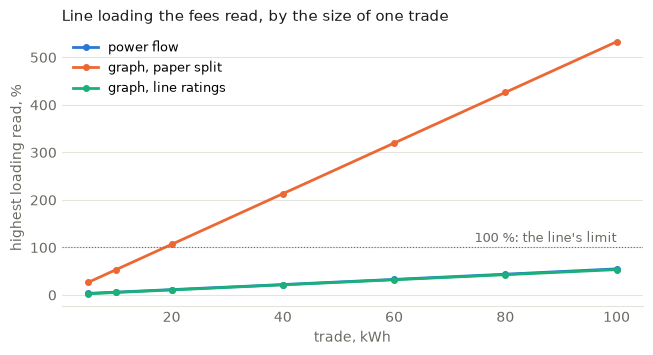

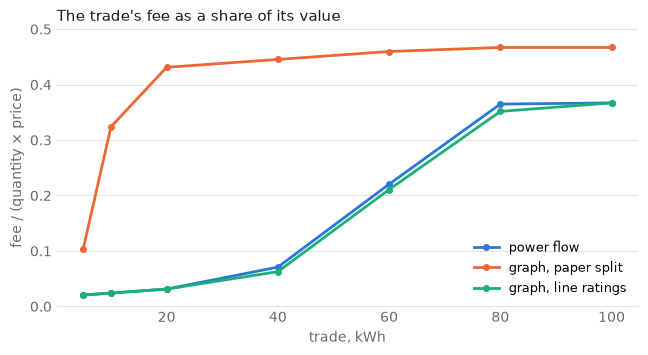

In [15]:
rows = []
for kwh in (5, 10, 20, 40, 60, 80, 100):
    for name, method in METHODS.items():
        m = market(grid=method, gen={"P13": kwh}, dem={"P11": kwh})
        r = step(m, [sell("P13", kwh, 0.20), buy("P11", kwh, 0.20)])
        t = r.trades[0]
        value = t.quantity * t.price
        row = {"trade kWh": kwh, "fees read from": name,
               "loading read %": (r.signal or r.grid).max_line_loading_percent,
               "measured %": r.grid.max_line_loading_percent,
               "highest voltage pu": r.grid.max_voltage_pu,
               "violations": len(r.grid.violations),
               "fee, share of value": t.fees / value}
        row.update({part: getattr(t.fee_parts, part) / value for part in ("congestion", "thermal", "voltage", "transmission")})
        rows.append(row)

sizes = pd.DataFrame(rows)
display(sizes.pivot(index="trade kWh", columns="fees read from", values="loading read %").round(1))

colors = dict(zip(METHODS, (BLUE, ORANGE, AQUA)))

fig, ax = axes("Line loading the fees read, by the size of one trade", "trade, kWh", "highest loading read, %")
for name in METHODS:
    part = sizes[sizes["fees read from"] == name]
    ax.plot(part["trade kWh"], part["loading read %"], color=colors[name], linewidth=2, marker="o", markersize=4, label=name)
ax.axhline(100, color=MUTED, linewidth=0.8, linestyle=":")
ax.annotate("100 %: the line's limit", (100, 100), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=9, color=MUTED)
ax.legend(frameon=False, fontsize=9)
plt.show()

fig, ax = axes("The trade's fee as a share of its value", "trade, kWh", "fee / (quantity × price)")
for name in METHODS:
    part = sizes[sizes["fees read from"] == name]
    ax.plot(part["trade kWh"], part["fee, share of value"], color=colors[name], linewidth=2, marker="o", markersize=4, label=name)
ax.set_ylim(0, 0.5)
ax.legend(frameon=False, fontsize=9)
plt.show()

The paper split reads about nine times the measured loading, so from a trade of
20 kWh on it is past 100 % and the fee sits at its ceiling: 10 % congestion plus
30 % thermal (plus voltage and losses), whatever the size. The ratings variant
follows the power flow closely **for traded energy**.

> **Question (MP-4e).** Which total capacity should the paper split use? As it
> stands, the `graph` arm charges close to the maximum fee on any cross-feeder
> trade of some size.

## 6. Voltage breaks first

The same sweep, read for the network's limits and for the parts of the fee, with
the power flow. The limits are 100 % line loading and voltages between 0.95 and
1.05 pu.

,measured %,highest voltage pu,violations,congestion,thermal,voltage,transmission,"fee, share of value"
trade kWh,,,,,,,,
5,3.47,1.0258,0,0.0,0.0000,0.0035,0.017,0.0205
10,6.09,1.0276,0,0.0,0.0000,0.0070,0.017,0.0240
20,11.36,1.0313,0,0.0,0.0000,0.0142,0.017,0.0312
40,22.03,1.0385,0,0.0,0.0254,0.0284,0.017,0.0708
60,32.85,1.0455,0,0.0,0.1606,0.0427,0.017,0.2203
80,43.83,1.0524,4,0.0,0.2979,0.0500,0.017,0.3649
100,54.98,1.0592,9,0.0,0.3000,0.0500,0.017,0.3670


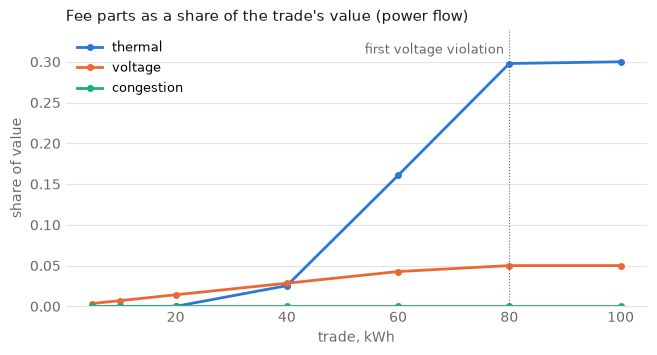

In [16]:
pf = sizes[sizes["fees read from"] == "power flow"].set_index("trade kWh")
display(pf[["measured %", "highest voltage pu", "violations", "congestion", "thermal", "voltage", "transmission", "fee, share of value"]].round(4))

fig, ax = axes("Fee parts as a share of the trade's value (power flow)", "trade, kWh", "share of value")
for part, color in (("thermal", BLUE), ("voltage", ORANGE), ("congestion", AQUA)):
    ax.plot(pf.index, pf[part], color=color, linewidth=2, marker="o", markersize=4, label=part)
first = pf.index[pf["violations"] > 0].min()
ax.axvline(first, color=MUTED, linewidth=0.8, linestyle=":")
ax.annotate("first voltage violation", (first, 0.31), xytext=(-4, 0), textcoords="offset points", ha="right", fontsize=9, color=MUTED)
ax.set_ylim(0, 0.34)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.show()

- The **voltage** limit is passed at 80 kWh, with the lines at 44 %.
- The **voltage** part of the fee is capped at 5 % of the value (`voltage_threshold`).
- The **thermal** part starts at 20 % loading and is at its 30 % cap by 44 %.
- The **congestion** part starts at 80 % loading, which 100 kWh does not reach.

So the fee that grows with the trade is the thermal one, and it stops growing
about where the first violation appears.

> **Question.** Are these thresholds what the stress scenario should price
> (MP-4i), given that voltage is the limit this network reaches first?

## 7. The zone bonus

A trade between two participants on the same feeder gets $-0.15 \cdot q \cdot p$
(`zone`, [P1] eq. 8e; M-33, M-34). At normal loading the other parts are far
smaller, so the total fee is negative: the DSO pays the two traders.

**The case.** P2 and P6 are 4 m apart on one feeder, each with a battery at 5 kWh
and nothing else: no load, no generation. They pass energy back and forth at 0.30,
as much as the batteries allow, swapping roles every step.

**One trade: P2 sells 3 kWh from its battery to P6 at 0.20**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,0.0,sell 3 @ 0.2,3 @ 0.2,-3,0,-0.0,1.8421,0.6,0.045,-0.0,0.0,0.645
P6,0.0,0.0,buy 3 @ 0.2,3 @ 0.2,3,0,-0.0,7.8500,-0.6,0.045,-0.0,0.0,-0.555


,stage,seller,buyer,kWh,price,value EUR,km,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P2,P6,3,0.2,0.6,0.0036,0.0001,-0.09,-0.0899,-0.045,-0.045


loading the fees read: 1.8 %, measured: 1.8 %, network losses: 1.27 kWh, participants +0.0899 + DSO -0.0899 = -0.0000 EUR


,seller,traded kWh,bought from DSO kWh,P2 battery,P6 battery,P2 bill,P6 bill,DSO has paid out EUR
step,,,,,,,,
0,P2,3.800,0.411,1.00,9.000,1.225,-1.179,0.171
1,P6,5.000,0.000,5.75,3.737,-1.388,1.612,0.396
2,P2,4.512,0.487,1.00,8.487,1.455,-1.400,0.599
3,P6,5.000,0.000,5.75,3.224,-1.388,1.612,0.823
4,P2,4.512,0.487,1.00,7.974,1.455,-1.400,1.026
5,P6,5.000,0.000,5.75,2.711,-1.388,1.612,1.251
6,P2,4.512,0.487,1.00,7.461,1.455,-1.400,1.454
7,P6,5.000,0.000,5.75,2.197,-1.388,1.612,1.679
8,P2,4.512,0.487,1.00,6.947,1.455,-1.401,1.882


after 12 steps: bills together +1.67 EUR, 56.4 kWh traded, stored energy 10.0 -> 6.92 kWh


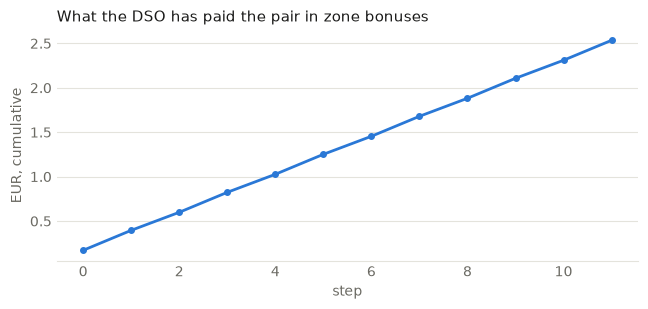

In [17]:
_ = case("One trade: P2 sells 3 kWh from its battery to P6 at 0.20",
         orders=[sell("P2", 3, 0.20), buy("P6", 3, 0.20)], soc={"P2": 5, "P6": 5})

m = market(soc={"P2": 5, "P6": 5})
rows, paid_out, stored = [], 0.0, None
for n in range(12):
    seller, buyer = ("P2", "P6") if n % 2 == 0 else ("P6", "P2")
    r = step(m, [sell(seller, 100, 0.30), buy(buyer, 100, 0.30)])
    paid_out += -sum(t.fees for t in r.trades if t.stage < 3)
    rows.append({
        "step": n,
        "seller": seller,
        "traded kWh": r.p2p_kwh,
        "bought from DSO kWh": r.dso_kwh,
        "P2 battery": r.participants["P2"].soc_kwh,
        "P6 battery": r.participants["P6"].soc_kwh,
        "P2 bill": net_bill(r, "P2"),
        "P6 bill": net_bill(r, "P6"),
        "DSO has paid out EUR": paid_out,
    })

wash = pd.DataFrame(rows).set_index("step")
display(wash.round(3))
print(f"after 12 steps: bills together {wash['P2 bill'].sum() + wash['P6 bill'].sum():+.2f} EUR, "
      f"{wash['traded kWh'].sum():.1f} kWh traded, stored energy {5 + 5:.1f} -> "
      f"{wash['P2 battery'].iloc[-1] + wash['P6 battery'].iloc[-1]:.2f} kWh")

fig, ax = axes("What the DSO has paid the pair in zone bonuses", "step", "EUR, cumulative", height=3.0)
ax.plot(wash.index, wash["DSO has paid out EUR"], color=BLUE, linewidth=2, marker="o", markersize=4)
plt.show()

The energy only moves between two batteries and loses about 10 % each round trip
(stored energy falls from 10.0 to 6.9 kWh, with 2.9 kWh bought from the DSO on the
way), yet the pair ends 1.67 EUR ahead: the DSO paid out 2.53 EUR in bonuses. The bonus grows with the price, so trading at the
highest allowed price pays most; the price itself is a transfer between the two
and costs the pair nothing.

> **Question.** Let the bonus lower a trade's fee to 0 but not below (no payout)?

## 8. Peer prices outside the tariffs

The market limits an order's price to its own range, 0 to 1
([`LocalEnergyMarket._validate`](../../../core/market/lem.py)), not to the DSO's
tariffs. Two peers can therefore trade above the utility price or below the
feed-in tariff.

A trained agent cannot do this: [`MarketEnv.decode`](../../../core/env/market_env.py)
maps its price into the range from the feed-in tariff to the peer ceiling. It can
only come from scripted orders or a bidding rule.

In [18]:
_ = case("P3 asks 0.50, P5 bids 0.90: they trade at 0.70, with the DSO selling at 0.30",
         orders=[sell("P3", 4, 0.50), buy("P5", 3, 0.90)], gen={"P3": 5}, dem={"P3": 1, "P5": 3})
_ = case("P3 asks 0.01, P5 bids 0.05: they trade at 0.03, with the DSO buying at 0.08",
         orders=[sell("P3", 4, 0.01), buy("P5", 3, 0.05)], gen={"P3": 5}, dem={"P3": 1, "P5": 3})

**P3 asks 0.50, P5 bids 0.90: they trade at 0.70, with the DSO selling at 0.30**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.5,4 @ 0.5,-3,-1,-0.0,2.18,0.1570,-0.0,0.0,2.3370
P5,0.0,3.0,buy 3 @ 0.9,3 @ 0.9,3,0,-0.0,-2.10,0.1572,-0.0,0.0,-1.9428


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3,0.70,2.10,0.0084,0.0,0.0005,-0.315,-0.3145,-0.1572,-0.1572
1,3,P3,DSO,1,0.08,0.08,0.0921,0.0,0.0002,0.000,0.0002,0.0000,0.0002


loading the fees read: 1.6 %, measured: 1.6 %, network losses: 1.27 kWh, participants +0.3942 + DSO -0.3942 = +0.0000 EUR


**P3 asks 0.01, P5 bids 0.05: they trade at 0.03, with the DSO buying at 0.08**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.01,4 @ 0.01,-3,-1,-0.0,0.17,0.0065,-0.0,0.0,0.1765
P5,0.0,3.0,buy 3 @ 0.05,3 @ 0.05,3,0,-0.0,-0.09,0.0067,-0.0,0.0,-0.0833


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P3,P5,3,0.03,0.09,0.0084,0.0,0.0000,-0.0135,-0.0135,-0.0067,-0.0067
1,3,P3,DSO,1,0.08,0.08,0.0921,0.0,0.0002,0.0000,0.0002,0.0000,0.0002


loading the fees read: 1.6 %, measured: 1.6 %, network losses: 1.27 kWh, participants +0.0932 + DSO -0.0932 = +0.0000 EUR


> **Question.** Limit order prices to the tariffs in the market as well, or leave
> that to the environment?

## 9. The buy limit and own surplus

What a participant may buy is its deficit plus what its battery can take:
$q_\text{buy,max} = \max(0, D - G) + E_\text{chargeable}$
([`Participant.max_buy_kwh`](../../../core/market/agent/der.py), [P1] eq. 15b). Its
own surplus is not counted. The sell limit was changed for the mirror case
(MP-2c); the buy limit follows the paper.

**The case.** P2 is given generation 6 and load 1 (surplus 5) and a battery at
5 kWh, which can take 4.21 kWh.

**In the thesis scenario no participant has both PV and a battery**, so this
cannot happen in the final runs.

In [19]:
SURPLUS = dict(gen={"P2": 6}, dem={"P2": 1}, soc={"P2": 5})

_ = case("No order: the surplus fills the battery, the rest is exported", **SURPLUS)
_ = case("Buys as much as it may: 4.21 kWh from the DSO at 0.30, while its own 5 kWh leave at 0.08",
         orders=[buy("P2", 100, 0.30)], **SURPLUS)

**No order: the surplus fills the battery, the rest is exported**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,6.0,1.0,-,-,0,0,-0.7895,9.0,0,-0.0,-0.0,0.0632,0.0632


loading the fees read: 1.4 %, measured: 1.4 %, network losses: 1.27 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR


**Buys as much as it may: 4.21 kWh from the DSO at 0.30, while its own 5 kWh leave at 0.08**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,6.0,1.0,buy 100 @ 0.3,4.211 @ 0.3,0,4.2105,-5.0,9.0,-1.2632,-0.0154,-0.0,0.4,-0.8786


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,fee EUR,buyer pays,seller pays
0,3,DSO,P2,4.2105,0.3,1.2632,0.3975,0.0004,0.0151,0.0154,0.0154,0.0


validation: P2: 100.00 kWh limited to 4.21
loading the fees read: 1.4 %, measured: 1.4 %, network losses: 1.27 kWh, participants -1.2786 + DSO +1.2786 = +0.0000 EUR


The battery ends at 9 kWh both times; the second bill is 0.94 EUR worse.

> **Question.** Count the surplus against the buy limit,
> $q_\text{buy,max} = \max(0, D - G + E_\text{chargeable})$, as MP-2c does on the
> sell side?

## 10. Smaller ones

**Stored energy is free in the bill (MP-1c).** The same deficit of 3 kWh: covered
from the battery it costs nothing, bought it costs 0.91 EUR and leaves the battery
full. The bill does not see the 3.16 kWh the battery lost.

In [20]:
_ = case("Deficit 3 kWh, no order", dem={"P2": 3}, soc={"P2": 5})
_ = case("Deficit 3 kWh, buys 3 kWh", orders=[buy("P2", 3, 0.30)], dem={"P2": 3}, soc={"P2": 5})

**Deficit 3 kWh, no order**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,3.0,-,-,0,0,-0.0,1.8421,0,-0.0,-0.0,0.0,0.0


loading the fees read: 1.4 %, measured: 1.4 %, network losses: 1.27 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR


**Deficit 3 kWh, buys 3 kWh**

,G,D,order,placed,peer,dso,untraded,battery after,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,,
P2,0.0,3.0,buy 3 @ 0.3,3 @ 0.3,0,3,-0.0,5,-0.9,-0.0128,-0.0,0.0,-0.9128


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,fee EUR,buyer pays,seller pays
0,3,DSO,P2,3,0.3,0.9,0.3975,0.0021,0.0107,0.0128,0.0128,0.0


loading the fees read: 2.9 %, measured: 2.9 %, network losses: 1.28 kWh, participants -0.9128 + DSO +0.9128 = +0.0000 EUR


**Ties go to the participant listed first.** Two sellers at the same price and the
same reputation: the auction takes them in the scenario's order
([`Clearing.double_auction`](../../../core/market/clearing.py)). P1 sells, P3 is
left for the DSO.

In [21]:
_ = case("P1 and P3 both ask 0.15; P5 bids 0.25 for 3 kWh",
         orders=[sell("P3", 4, 0.15), sell("P1", 3, 0.15), buy("P5", 3, 0.25)],
         gen={"P3": 5, "P1": 3}, dem={"P3": 1, "P5": 3})

**P1 and P3 both ask 0.15; P5 bids 0.25 for 3 kWh**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P1,3.0,0.0,sell 3 @ 0.15,3 @ 0.15,-3,0,-0.0,0.60,0.0446,-0.0,0.0,0.6446
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,0,-4,-0.0,0.32,-0.0010,-0.0,0.0,0.3190
P5,0.0,3.0,buy 3 @ 0.25,3 @ 0.25,3,0,-0.0,-0.60,0.0446,-0.0,0.0,-0.5554


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,zone,fee EUR,buyer pays,seller pays
0,2,P1,P5,3,0.20,0.60,0.0369,0.0001,0.0007,-0.09,-0.0893,-0.0446,-0.0446
1,3,P3,DSO,4,0.08,0.32,0.0921,0.0001,0.0009,0.00,0.0010,0.0000,0.0010


loading the fees read: 1.9 %, measured: 1.9 %, network losses: 1.27 kWh, participants +0.4083 + DSO -0.4083 = -0.0000 EUR


**A tiny order still counts for reputation.** An order of 0.0000001 kWh is placed,
trades nothing, and lowers the reputation like any order that found no peer. The
environment drops orders below 5 % of the limit, so this needs a scripted order.

In [22]:
m, r = case("P5 places an order of 0.0000001 kWh", orders=[buy("P5", 1e-7, 0.25)], gen={"P3": 5}, dem={"P3": 1, "P5": 3})
print("reputation after the step:", {pid: round(m.participants[pid].reputation, 3) for pid in ("P3", "P5")})

**P5 places an order of 0.0000001 kWh**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,-,-,0,0,-4.0,0,-0.0,-0.0,0.32,0.32
P5,0.0,3.0,buy 1e-07 @ 0.25,1e-07 @ 0.25,0,0,3.0,0,-0.0,-0.0,-0.90,-0.90


loading the fees read: 1.6 %, measured: 1.6 %, network losses: 1.27 kWh, participants +0.0000 + DSO +0.0000 = +0.0000 EUR
reputation after the step: {'P3': 0.5, 'P5': 0.5}


**Naming the DSO as partner still works in the market.** The environment no longer
offers it (RP-1h), but an order that names `DSO` skips the auction and goes
straight to stage 3. Here it also pays the imbalance fee.

In [23]:
_ = case("P4 names the DSO; P3 could have sold to it",
         orders=[sell("P3", 4, 0.15), buy("P4", 2, 0.25, DSO_ID)], gen={"P3": 5}, dem={"P3": 1, "P4": 2})

**P4 names the DSO; P3 could have sold to it**

,G,D,order,placed,peer,dso,untraded,trades EUR,fees EUR,loss charge EUR,untraded EUR,bill EUR
id,,,,,,,,,,,,
P3,5.0,1.0,sell 4 @ 0.15,4 @ 0.15,0,-4,-0.0,0.32,-0.0010,-0.0,0.0,0.3190
P4,0.0,2.0,buy 2 @ 0.25 -> DSO,2 @ 0.25,0,2,-0.0,-0.60,-0.0923,-0.0,0.0,-0.6923


,stage,seller,buyer,kWh,price,value EUR,km,voltage,transmission,imbalance,fee EUR,buyer pays,seller pays
0,3,P3,DSO,4,0.08,0.32,0.0921,0.0002,0.0009,0.00,0.0010,0.0000,0.001
1,3,DSO,P4,2,0.30,0.60,0.1075,0.0004,0.0019,0.09,0.0923,0.0923,0.000


loading the fees read: 2.4 %, measured: 2.4 %, network losses: 1.27 kWh, participants -0.3733 + DSO +0.3733 = +0.0000 EUR


## The questions in one place

| # | Question |
|---|---|
| 1 | Loss charge: leave the transformer's loss out of the sharing? |
| 2 | Fees on untraded energy too, or none on orders the DSO clears? (MP-1e, M-31) |
| 3 | Imbalance fee: keep, drop, or smooth? |
| 4 | Is "the power flow charges the trade on a loaded line, the graph model only traded energy" the contrast the thesis wants? |
| 5 | The paper split's total capacity (MP-4e) |
| 6 | Fee thresholds against the limit reached first, voltage (MP-4i) |
| 7 | Zone bonus: no lower than a fee of 0? (M-33, M-34) |
| 8 | Order prices limited to the tariffs in the market? |
| 9 | Buy limit: count own surplus? (MP-2c) |
| 10 | Stored energy in the bill (MP-1c); ties; tiny orders; DSO as partner |